In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution, minimize
from scipy.spatial import ConvexHull, QhullError

plt.style.use(style="seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)

In [54]:
from __future__ import annotations
from numpy.typing import NDArray

In [55]:
def jones_ar_coefficients(p: int, rng: np.random.Generator | int | None = None, *, return_pacf: bool = False):
    if not isinstance(p, (int, np.integer)) or p < 1:
        raise ValueError(f"p must be a positive integer, got {p}")
    generator = np.random.default_rng(rng)
    k = np.arange(1, p + 1)
    a = (k + 1) // 2
    b = k // 2 + 1
    beta_draws = generator.beta(a, b)
    pacf = 2.0 * beta_draws - 1.0
    phi = np.array([pacf[0]], dtype=float)
    for order in range(2, p + 1):
        reflection_coeff = pacf[order - 1]
        previous_phi = phi
        phi = np.empty(order, dtype=float)
        phi[:-1] = (previous_phi - reflection_coeff * previous_phi[::-1])
        phi[-1] = reflection_coeff
    if return_pacf:
        return phi, pacf
    return phi

def simulate_uniform_ar(phi, sample_size: int, burnin: int=500, half_width=1.0, rng=None):
    phi = np.asarray(phi, dtype=float)
    if phi.ndim != 1 or len(phi) == 0:
        raise ValueError("phi must be a nonempty one-dimensional coefficient vector")
    if not isinstance(sample_size, (int, np.integer)) or sample_size < 1:
        raise ValueError("sample_size must be a positive integer")
    if not isinstance(burnin, (int, np.integer)) or burnin < 0:
        raise ValueError("burnin must be a non-negative integer")
    if half_width <= 0:
        raise ValueError("half_width must be a positive number")
    generator = np.random.default_rng(rng)
    order = len(phi)
    total_length = burnin + order + sample_size
    innovations = generator.uniform(-half_width, half_width, size=total_length)
    series = np.zeros(total_length, dtype=float)
    for t in range(order, total_length):
        recent_values = series[t - np.arange(1, order + 1)]
        series[t] = phi @ recent_values + innovations[t]
    return series[burnin + order:]

phi: [-1.0876 -0.9523]


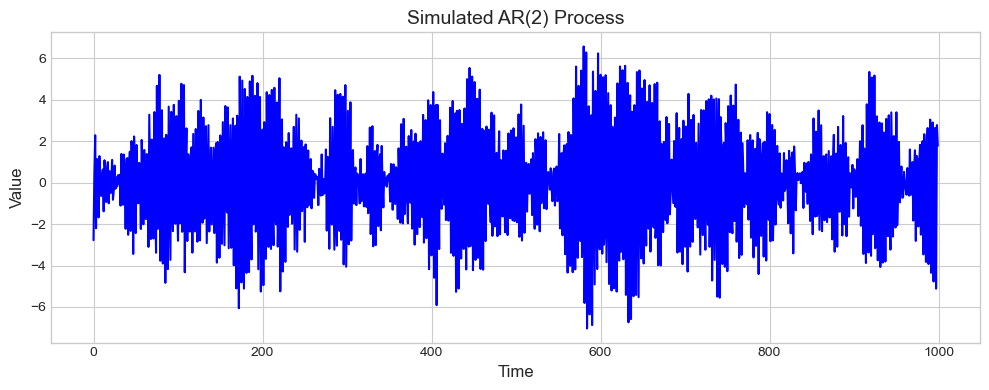

In [56]:
p = 2
coefficient_seed = 42
process_seed = 20260806
sample_size = 1000
burnin = 500
innovations_half_width = 1.0

phi = jones_ar_coefficients(p, rng=coefficient_seed, return_pacf=False)
ar_series = simulate_uniform_ar(phi, sample_size, burnin, innovations_half_width, rng=process_seed)

print("phi:", phi)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ar_series, color="blue", linewidth=1.5)
ax.set_title(f"Simulated AR({p}) Process", fontsize=14)
ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Value", fontsize=12)
plt.tight_layout()
plt.show()

In [57]:
def ar_impulse_response(phi, maximum_lag):
    phi = np.asarray(phi, dtype=float)
    order = len(phi)
    psi = np.zeros(maximum_lag + 1)
    psi[0] = 1.0
    for lag in range(1, maximum_lag + 1):
        psi[lag] = sum(phi[j - 1] * psi[lag - j] for j in range(1, min(order, lag) + 1))
    return psi

In [58]:
def sliding_window_point_cloud(series, embedding_dimension: int):
    series = np.asarray(series, dtype=float)
    k = int(embedding_dimension)
    if series.ndim != 1:
        raise ValueError("series must be a one-dimensional array")
    if k < 1 or len(series) < k:
        raise ValueError("embedding_dimension must be a positive integer less than or equal to the length of the series")
    return np.column_stack([series[k - 1 - lag:len(series) - lag] for lag in range(k)])

In [59]:
def projected_subgradient_empirical_width(
    points,
    iterations=2_000,
    initial_step=0.2,
    patience=200,
    improvement_tolerance=1e-10,
    rng=None,
    initial_direction=None,
):
    """Minimize empirical directional width over the unit sphere."""
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or len(points) < 2:
        raise ValueError("points must have shape (n, k) with n >= 2.")
    if iterations < 1:
        raise ValueError("iterations must be positive.")
    if initial_step <= 0:
        raise ValueError("initial_step must be positive.")
    if not isinstance(patience, (int, np.integer)) or patience < 1:
        raise ValueError("patience must be a positive integer.")
    if improvement_tolerance < 0:
        raise ValueError("improvement_tolerance must be nonnegative.")

    generator = np.random.default_rng(rng)
    dimension = points.shape[1]

    if initial_direction is None:
        direction = generator.normal(size=dimension)
    else:
        direction = np.asarray(initial_direction, dtype=float)
        if direction.shape != (dimension,):
            raise ValueError(f"initial_direction must have shape ({dimension},).")

    direction_norm = np.linalg.norm(direction)
    if direction_norm <= np.finfo(float).eps:
        raise ValueError("initial_direction must be nonzero.")
    direction = direction / direction_norm

    width_history = np.empty(iterations)
    best_width_history = np.empty(iterations)
    best_width = np.inf
    best_direction = direction.copy()
    iterations_without_improvement = 0

    for iteration in range(iterations):
        projections = points @ direction
        maximum_index = int(np.argmax(projections))
        minimum_index = int(np.argmin(projections))
        width = projections[maximum_index] - projections[minimum_index]

        if width < best_width - improvement_tolerance:
            best_width = float(width)
            best_direction = direction.copy()
            iterations_without_improvement = 0
        else:
            iterations_without_improvement += 1

        width_history[iteration] = width
        best_width_history[iteration] = best_width

        if iterations_without_improvement >= patience:
            width_history = width_history[:iteration + 1]
            best_width_history = best_width_history[:iteration + 1]
            break

        # x_max-x_min is a subgradient of max_i <x_i,u>-min_i <x_i,u>.
        subgradient = points[maximum_index] - points[minimum_index]
        subgradient_norm = np.linalg.norm(subgradient)
        if subgradient_norm <= np.finfo(float).eps:
            width_history = width_history[:iteration + 1]
            best_width_history = best_width_history[:iteration + 1]
            break

        # Use a decreasing step and project the update back onto the unit sphere.
        step = initial_step / np.sqrt(iteration + 1.0)
        candidate = direction - step * subgradient / subgradient_norm
        candidate_norm = np.linalg.norm(candidate)
        if candidate_norm <= np.finfo(float).eps:
            candidate = generator.normal(size=dimension)
            candidate_norm = np.linalg.norm(candidate)
        direction = candidate / candidate_norm

    return {
        "minimum_width": best_width,
        "direction": best_direction,
        "width_history": width_history,
        "best_width_history": best_width_history,
    }


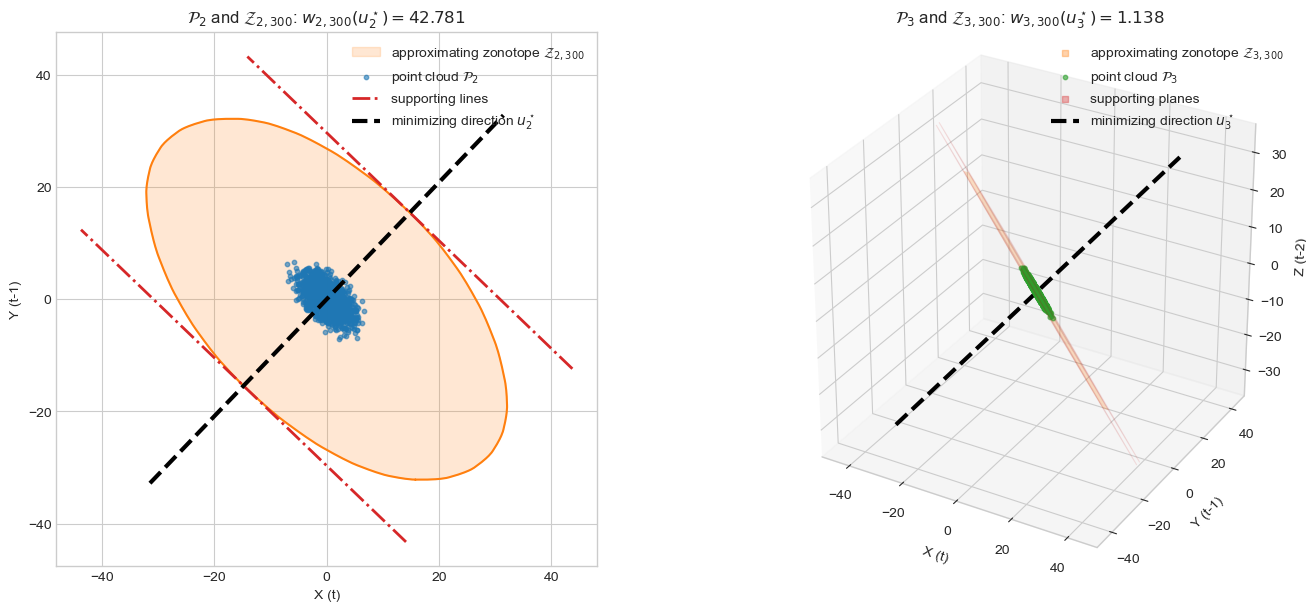

In [60]:
cloud_2d = sliding_window_point_cloud(ar_series, embedding_dimension=2)
cloud_3d = sliding_window_point_cloud(ar_series, embedding_dimension=3)

subgradient_2d = projected_subgradient_empirical_width(
    cloud_2d,
    iterations=2_000,
    initial_step=0.2,
    rng=20260806,
)
subgradient_3d = projected_subgradient_empirical_width(
    cloud_3d,
    iterations=2_000,
    initial_step=0.2,
    rng=20260807,
)

theoretical_history = 10_000
psi_for_cloud_plot = ar_impulse_response(phi, theoretical_history)
psi_shifted_once = np.concatenate(([0.0], psi_for_cloud_plot[:-1]))

def theoretical_width_2d_from_angle(angle):
    direction = np.array([np.cos(angle), np.sin(angle)])
    generator_projections = (
        direction[0] * psi_for_cloud_plot
        + direction[1] * psi_shifted_once
    )
    return float(
        2.0 * innovations_half_width * np.sum(np.abs(generator_projections))
    )

angle_grid = np.linspace(0.0, np.pi, 721, endpoint=False)
width_grid = np.array([theoretical_width_2d_from_angle(angle) for angle in angle_grid])
best_grid_angle = angle_grid[np.argmin(width_grid)]
theoretical_fit_2d = minimize(
    lambda angle: theoretical_width_2d_from_angle(float(angle[0])),
    x0=np.array([best_grid_angle]),
    method="Nelder-Mead",
    options={"xatol": 1e-12, "fatol": 1e-12},
)
theoretical_angle_2d = float(theoretical_fit_2d.x[0] % np.pi)
theoretical_direction_2d = np.array([
    np.cos(theoretical_angle_2d),
    np.sin(theoretical_angle_2d),
])
theoretical_minimum_width_2d = theoretical_width_2d_from_angle(
    theoretical_angle_2d
)

theoretical_direction_3d = np.concatenate(([1.0], -phi))
theoretical_direction_3d /= np.linalg.norm(theoretical_direction_3d)
generator_projections_3d = np.convolve(
    psi_for_cloud_plot, theoretical_direction_3d
)[: theoretical_history + 1]
theoretical_minimum_width_3d = float(
    2.0 * innovations_half_width * np.sum(np.abs(generator_projections_3d))
)

# Use a finite impulse-response history to obtain drawable approximations
# Z_(k,H) of the infinite theoretical support zonotopes.
zonotope_history = 300

def ar_window_zonotope_generators(phi, embedding_dimension, history, half_width=1.0):
    psi = ar_impulse_response(phi, history)
    generators = np.zeros((embedding_dimension, history + 1))
    for innovation_lag in range(history + 1):
        for coordinate in range(embedding_dimension):
            response_lag = innovation_lag - coordinate
            if response_lag >= 0:
                generators[coordinate, innovation_lag] = (
                    half_width * psi[response_lag]
                )
    return generators[:, np.linalg.norm(generators, axis=0) > 1e-13]


def zonotope_polygon_2d(generators):
    # A planar zonotope has two boundary edges parallel to every generator.
    lengths = np.linalg.norm(generators, axis=0)
    angles = np.mod(np.arctan2(generators[1], generators[0]), np.pi)
    oriented = lengths[:, None] * np.column_stack((np.cos(angles), np.sin(angles)))
    oriented = oriented[np.argsort(angles)]

    current = -np.sum(oriented, axis=0)
    vertices = [current.copy()]
    for generator in oriented:
        current = current + 2.0 * generator
        vertices.append(current.copy())
    for generator in oriented:
        current = current - 2.0 * generator
        vertices.append(current.copy())
    return np.asarray(vertices)


def fibonacci_sphere_directions(number_of_directions):
    index = np.arange(number_of_directions)
    z = 1.0 - 2.0 * (index + 0.5) / number_of_directions
    radius = np.sqrt(1.0 - z**2)
    angle = np.pi * (3.0 - np.sqrt(5.0)) * index
    return np.column_stack((radius * np.cos(angle), radius * np.sin(angle), z))


def zonotope_support_points(generators, directions):
    # The support point in direction u is sum_j sign(<g_j,u>) g_j.
    signs = np.sign(generators.T @ directions.T)
    signs[signs == 0.0] = 1.0
    return (generators @ signs).T


generators_2d = ar_window_zonotope_generators(
    phi, 2, zonotope_history, innovations_half_width
)
generators_3d = ar_window_zonotope_generators(
    phi, 3, zonotope_history, innovations_half_width
)
zonotope_vertices_2d = zonotope_polygon_2d(generators_2d)

sphere_directions = fibonacci_sphere_directions(1_200)
sphere_directions = np.vstack((
    sphere_directions,
    theoretical_direction_3d,
    -theoretical_direction_3d,
))
zonotope_surface_points_3d = zonotope_support_points(
    generators_3d, sphere_directions
)
zonotope_hull_3d = ConvexHull(zonotope_surface_points_3d)

# The two support levels are +/-h, so their separation is the finite-history width 2h.
support_half_width_2d = np.sum(
    np.abs(generators_2d.T @ theoretical_direction_2d)
)
support_half_width_3d = np.sum(
    np.abs(generators_3d.T @ theoretical_direction_3d)
)
approximating_width_2d = 2.0 * support_half_width_2d
approximating_width_3d = 2.0 * support_half_width_3d

perpendicular_2d = np.array([
    -theoretical_direction_2d[1], theoretical_direction_2d[0]
])
perpendicular_coordinates_2d = zonotope_vertices_2d @ perpendicular_2d
support_line_coordinate = np.linspace(
    perpendicular_coordinates_2d.min(),
    perpendicular_coordinates_2d.max(),
    2,
)

reference_axis = np.array([0.0, 0.0, 1.0])
if abs(theoretical_direction_3d @ reference_axis) > 0.9:
    reference_axis = np.array([0.0, 1.0, 0.0])
plane_basis_1 = np.cross(theoretical_direction_3d, reference_axis)
plane_basis_1 /= np.linalg.norm(plane_basis_1)
plane_basis_2 = np.cross(theoretical_direction_3d, plane_basis_1)
plane_coordinate_1 = zonotope_surface_points_3d @ plane_basis_1
plane_coordinate_2 = zonotope_surface_points_3d @ plane_basis_2
plane_grid_1, plane_grid_2 = np.meshgrid(
    np.linspace(plane_coordinate_1.min(), plane_coordinate_1.max(), 2),
    np.linspace(plane_coordinate_2.min(), plane_coordinate_2.max(), 2),
)

direction_half_length_2d = 0.5 * np.linalg.norm(np.ptp(zonotope_vertices_2d, axis=0))
direction_endpoints_2d = np.outer(
    [-direction_half_length_2d, direction_half_length_2d],
    theoretical_direction_2d,
)
direction_half_length_3d = 0.5 * np.linalg.norm(
    np.ptp(zonotope_surface_points_3d, axis=0)
)
direction_endpoints_3d = np.outer(
    [-direction_half_length_3d, direction_half_length_3d],
    theoretical_direction_3d,
)

fig = plt.figure(figsize=(14, 6), constrained_layout=True)
ax_2d = fig.add_subplot(1, 2, 1)
ax_3d = fig.add_subplot(1, 2, 2, projection='3d')
ax_2d.fill(
    zonotope_vertices_2d[:, 0],
    zonotope_vertices_2d[:, 1],
    color="tab:orange",
    alpha=0.18,
    label=fr"approximating zonotope $\mathcal{{Z}}_{{2,{zonotope_history}}}$",
)
ax_2d.plot(
    zonotope_vertices_2d[:, 0],
    zonotope_vertices_2d[:, 1],
    color="tab:orange",
    linewidth=1.5,
)
ax_2d.scatter(
    cloud_2d[:, 0], cloud_2d[:, 1],
    color="tab:blue", s=10, alpha=0.6, label=r"point cloud $\mathcal{P}_2$"
)
for support_sign in (-1.0, 1.0):
    support_line = (
        support_sign * support_half_width_2d * theoretical_direction_2d
        + np.outer(support_line_coordinate, perpendicular_2d)
    )
    ax_2d.plot(
        support_line[:, 0], support_line[:, 1],
        color="tab:red", linestyle="-.", linewidth=2.0,
        label="supporting lines" if support_sign < 0 else None,
    )
ax_2d.plot(
    direction_endpoints_2d[:, 0],
    direction_endpoints_2d[:, 1],
    color="black",
    linestyle="--",
    linewidth=3,
    label=r"minimizing direction $u_2^\star$",
)
ax_2d.set_title(
    rf"$\mathcal{{P}}_2$ and $\mathcal{{Z}}_{{2,{zonotope_history}}}$: "
    rf"$w_{{2,{zonotope_history}}}(u_2^\star)={approximating_width_2d:.3f}$",
    fontsize=12,
)
ax_2d.set_xlabel("X (t)", fontsize=10)
ax_2d.set_ylabel("Y (t-1)", fontsize=10)
ax_2d.set_aspect("equal", adjustable="box")
ax_2d.legend(loc="upper right")
ax_3d.plot_trisurf(
    zonotope_surface_points_3d[:, 0],
    zonotope_surface_points_3d[:, 1],
    zonotope_surface_points_3d[:, 2],
    triangles=zonotope_hull_3d.simplices,
    color="tab:orange", alpha=0.12, linewidth=0.15, shade=False,
)
ax_3d.scatter([], [], [], color="tab:orange", marker="s", alpha=0.35,
              label=fr"approximating zonotope $\mathcal{{Z}}_{{3,{zonotope_history}}}$")
ax_3d.scatter(
    cloud_3d[:, 0], cloud_3d[:, 1], cloud_3d[:, 2],
    color="tab:green", s=10, alpha=0.6, label=r"point cloud $\mathcal{P}_3$"
)
for support_sign in (-1.0, 1.0):
    support_plane = (
        support_sign * support_half_width_3d * theoretical_direction_3d
        + plane_grid_1[..., None] * plane_basis_1
        + plane_grid_2[..., None] * plane_basis_2
    )
    ax_3d.plot_surface(
        support_plane[:, :, 0],
        support_plane[:, :, 1],
        support_plane[:, :, 2],
        color="tab:red", alpha=0.12, edgecolor="tab:red", linewidth=0.8,
    )
ax_3d.scatter([], [], [], color="tab:red", marker="s", alpha=0.35,
              label="supporting planes")
ax_3d.plot(
    direction_endpoints_3d[:, 0],
    direction_endpoints_3d[:, 1],
    direction_endpoints_3d[:, 2],
    color="black",
    linestyle="--",
    linewidth=3,
    label=r"minimizing direction $u_3^\star$",
)
ax_3d.set_title(
    rf"$\mathcal{{P}}_3$ and $\mathcal{{Z}}_{{3,{zonotope_history}}}$: "
    rf"$w_{{3,{zonotope_history}}}(u_3^\star)={approximating_width_3d:.3f}$",
    fontsize=12,
)
ax_3d.set_xlabel("X (t)", fontsize=10)
ax_3d.set_ylabel("Y (t-1)", fontsize=10)
ax_3d.set_zlabel("Z (t-2)", fontsize=10)
ax_3d.set_box_aspect(np.ptp(zonotope_surface_points_3d, axis=0))
ax_3d.legend(loc="upper right")
plt.show()

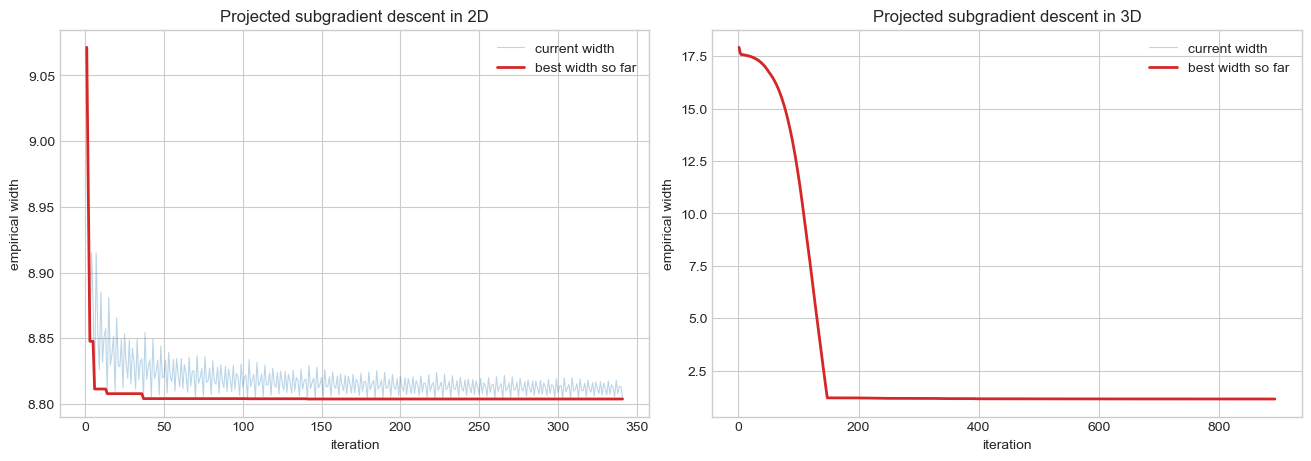

2D minimum width: 8.803727824421523
2D minimizing direction: [0.7343 0.6788]
3D minimum width: 1.1542180589044906
3D minimizing direction: [0.5707 0.6176 0.5412]


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

for axis, result, dimension in zip(
    axes,
    (subgradient_2d, subgradient_3d),
    (2, 3),
):
    iteration_numbers = np.arange(1, len(result["width_history"]) + 1)
    axis.plot(
        iteration_numbers,
        result["width_history"],
        color="tab:blue",
        alpha=0.3,
        linewidth=0.8,
        label="current width",
    )
    axis.plot(
        iteration_numbers,
        result["best_width_history"],
        color="tab:red",
        linewidth=2.0,
        label="best width so far",
    )
    axis.set(
        title=f"Projected subgradient descent in {dimension}D",
        xlabel="iteration",
        ylabel="empirical width",
    )
    axis.legend()

plt.show()

print("2D minimum width:", subgradient_2d["minimum_width"])
print("2D minimizing direction:", subgradient_2d["direction"])
print("3D minimum width:", subgradient_3d["minimum_width"])
print("3D minimizing direction:", subgradient_3d["direction"])


In [10]:
def first_plateau_selector(
    k_values,
    minimized_widths,
    relative_tolerance=0.10,
):
    """Return the first scale within a relative tolerance of the observed minimum."""
    k_values = np.asarray(k_values)
    minimized_widths = np.asarray(minimized_widths, dtype=float)

    if k_values.ndim != 1 or minimized_widths.ndim != 1:
        raise ValueError("k_values and minimized_widths must be one-dimensional.")
    if len(k_values) != len(minimized_widths):
        raise ValueError("k_values and minimized_widths must have equal lengths.")
    if len(k_values) == 0:
        raise ValueError("At least one scale is required.")
    if not np.all(np.isfinite(minimized_widths)):
        raise ValueError("All minimized widths must be finite.")
    if relative_tolerance < 0:
        raise ValueError("relative_tolerance must be nonnegative.")

    minimum_width = np.min(minimized_widths)
    plateau_threshold = minimum_width * (1.0 + relative_tolerance)
    first_plateau_index = np.flatnonzero(
        minimized_widths <= plateau_threshold
    )[0]

    return {
        "selected_k": int(k_values[first_plateau_index]),
        "minimum_width": float(minimum_width),
        "plateau_threshold": float(plateau_threshold),
        "relative_tolerance": float(relative_tolerance),
    }


plateau_relative_tolerance = 0.10


In [ ]:
def theoretical_ar_width_in_direction(
    phi,
    direction,
    half_width=1.0,
    history=10_000,
):
    """Evaluate the theoretical AR support width in a supplied direction."""
    direction = np.asarray(direction, dtype=float)
    direction_norm = np.linalg.norm(direction)

    if direction.ndim != 1 or len(direction) == 0:
        raise ValueError("direction must be a nonempty one-dimensional array.")
    if direction_norm == 0:
        raise ValueError("direction must be nonzero.")
    if half_width <= 0 or history < 0:
        raise ValueError("Require half_width > 0 and history >= 0.")

    unit_direction = direction / direction_norm
    psi = ar_impulse_response(phi, maximum_lag=history)

    # The convolution gives <g_j, u> for innovation lags j=0,...,history.
    generator_projections = np.convolve(psi, unit_direction)[: history + 1]

    # The support width is twice the sum of the absolute generator projections.
    return float(2.0 * half_width * np.sum(np.abs(generator_projections)))


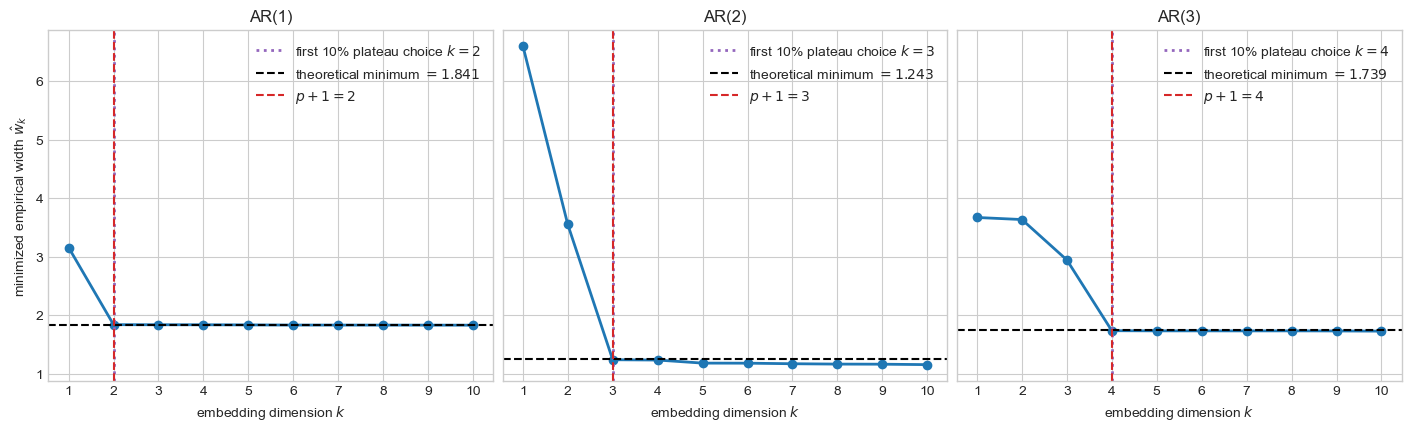

In [ ]:
experiment_orders = (1, 2, 3)
experiment_k_max = 10
experiment_sample_size = 2_000
experiment_burnin = 1_000
experiment_half_width = 1.0
experiment_iterations = 2_000
experiment_initial_step = 0.2
experiment_restarts = 8
experiment_seed = 20260808

experiment_rows = []

for order in experiment_orders:
    phi_order = jones_ar_coefficients(
        p=order,
        rng=experiment_seed + order,
    )
    series_order = simulate_uniform_ar(
        phi_order,
        sample_size=experiment_sample_size,
        burnin=experiment_burnin,
        half_width=experiment_half_width,
        rng=experiment_seed + 100 + order,
    )

    for k in range(1, experiment_k_max + 1):
        cloud_k = sliding_window_point_cloud(series_order, embedding_dimension=k)
        restart_fits = [
            projected_subgradient_empirical_width(
                cloud_k,
                iterations=experiment_iterations,
                initial_step=experiment_initial_step,
                rng=experiment_seed + 10_000 * order + 100 * k + restart,
            )
            for restart in range(experiment_restarts)
        ]
        width_fit = min(restart_fits, key=lambda fit: fit["minimum_width"])
        theoretical_direction_width = theoretical_ar_width_in_direction(
            phi_order,
            width_fit["direction"],
            half_width=experiment_half_width,
        )
        experiment_rows.append({
            "p": order,
            "k": k,
            "minimum_width": width_fit["minimum_width"],
            "minimizing_direction": width_fit["direction"].copy(),
            "theoretical_width_at_empirical_direction": theoretical_direction_width,
            "phi": phi_order.copy(),
        })

minimum_width_experiment = pd.DataFrame(experiment_rows)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True, sharey=True)

for axis, order in zip(axes, experiment_orders):
    order_results = minimum_width_experiment[
        minimum_width_experiment["p"] == order
    ]
    axis.plot(
        order_results["k"],
        order_results["minimum_width"],
        marker="o",
        linewidth=2.0,
        color="tab:blue",
        label=r"empirical minimum $\widehat{m}_k$",
    )
    axis.plot(
        order_results["k"],
        order_results["theoretical_width_at_empirical_direction"],
        marker="s",
        linestyle="-.",
        linewidth=1.8,
        color="tab:green",
        label=r"theoretical width $w_{K_k}(\widehat{u}_k)$",
    )

    plateau_fit = first_plateau_selector(
        order_results["k"].to_numpy(),
        order_results["minimum_width"].to_numpy(),
        relative_tolerance=plateau_relative_tolerance,
    )
    plateau_choice = plateau_fit["selected_k"]
    axis.axvline(
        plateau_choice,
        color="tab:purple",
        linestyle=":",
        linewidth=2.0,
        label=fr"first 10% plateau choice $k={plateau_choice}$",
    )

    phi_order = order_results["phi"].iloc[0]
    recurrence_vector = np.r_[1.0, -phi_order]
    theoretical_minimum_width = (
        2.0 * experiment_half_width / np.linalg.norm(recurrence_vector)
    )
    axis.axhline(
        theoretical_minimum_width,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=fr"theoretical minimum $={theoretical_minimum_width:.3f}$",
    )
    axis.axvline(
        order + 1,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        label=fr"$p+1={order + 1}$",
    )
    axis.set(
        title=fr"AR({order})",
        xlabel=r"embedding dimension $k$",
        xticks=np.arange(1, experiment_k_max + 1),
    )
    axis.legend()

axes[0].set_ylabel(r"minimized empirical width $\hat{w}_k$")
plt.show()


In [ ]:
experiment_orders_456 = (4, 5, 6)
experiment_k_max_456 = 10
experiment_seed_456 = 20260809
experiment_rows_456 = []

for order in experiment_orders_456:
    phi_order = jones_ar_coefficients(
        p=order,
        rng=experiment_seed_456 + order,
    )
    series_order = simulate_uniform_ar(
        phi_order,
        sample_size=experiment_sample_size,
        burnin=experiment_burnin,
        half_width=experiment_half_width,
        rng=experiment_seed_456 + 100 + order,
    )

    for k in range(1, experiment_k_max_456 + 1):
        cloud_k = sliding_window_point_cloud(series_order, embedding_dimension=k)
        restart_fits = [
            projected_subgradient_empirical_width(
                cloud_k,
                iterations=experiment_iterations,
                initial_step=experiment_initial_step,
                rng=experiment_seed_456 + 10_000 * order + 100 * k + restart,
            )
            for restart in range(experiment_restarts)
        ]
        width_fit = min(restart_fits, key=lambda fit: fit["minimum_width"])
        theoretical_direction_width = theoretical_ar_width_in_direction(
            phi_order,
            width_fit["direction"],
            half_width=experiment_half_width,
        )
        experiment_rows_456.append({
            "p": order,
            "k": k,
            "minimum_width": width_fit["minimum_width"],
            "minimizing_direction": width_fit["direction"].copy(),
            "theoretical_width_at_empirical_direction": theoretical_direction_width,
            "phi": phi_order.copy(),
        })

minimum_width_experiment_456 = pd.DataFrame(experiment_rows_456)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True, sharey=True)

for axis, order in zip(axes, experiment_orders_456):
    order_results = minimum_width_experiment_456[
        minimum_width_experiment_456["p"] == order
    ]
    axis.plot(
        order_results["k"],
        order_results["minimum_width"],
        marker="o",
        linewidth=2.0,
        color="tab:blue",
        label=r"empirical minimum $\widehat{m}_k$",
    )
    axis.plot(
        order_results["k"],
        order_results["theoretical_width_at_empirical_direction"],
        marker="s",
        linestyle="-.",
        linewidth=1.8,
        color="tab:green",
        label=r"theoretical width $w_{K_k}(\widehat{u}_k)$",
    )

    plateau_fit = first_plateau_selector(
        order_results["k"].to_numpy(),
        order_results["minimum_width"].to_numpy(),
        relative_tolerance=plateau_relative_tolerance,
    )
    plateau_choice = plateau_fit["selected_k"]
    axis.axvline(
        plateau_choice,
        color="tab:purple",
        linestyle=":",
        linewidth=2.0,
        label=fr"first 10% plateau choice $k={plateau_choice}$",
    )

    phi_order = order_results["phi"].iloc[0]
    recurrence_vector = np.r_[1.0, -phi_order]
    theoretical_minimum_width = (
        2.0 * experiment_half_width / np.linalg.norm(recurrence_vector)
    )
    axis.axhline(
        theoretical_minimum_width,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=fr"theoretical minimum $={theoretical_minimum_width:.3f}$",
    )
    axis.axvline(
        order + 1,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        label=fr"$p+1={order + 1}$",
    )
    axis.set(
        title=fr"AR({order})",
        xlabel=r"embedding dimension $k$",
        xticks=np.arange(1, experiment_k_max_456 + 1),
    )
    axis.legend()

axes[0].set_ylabel(r"minimized empirical width $\hat{w}_k$")
plt.show()


In [150]:
def aic_bic_ar_order(series, maximum_order):
    """Select conditional least-squares AR orders by Gaussian AIC and BIC."""
    series = np.asarray(series, dtype=float)
    maximum_order = int(maximum_order)
    if series.ndim != 1 or len(series) <= maximum_order + 1:
        raise ValueError("series is too short for the requested maximum_order.")

    # Use the same response times for every candidate so the criteria are comparable.
    response = series[maximum_order:]
    lag_matrix = np.column_stack([
        series[maximum_order - lag:len(series) - lag]
        for lag in range(1, maximum_order + 1)
    ])
    observation_count = len(response)
    criterion_rows = []

    for order in range(maximum_order + 1):
        if order == 0:
            design = np.ones((observation_count, 1))
        else:
            design = np.column_stack([
                np.ones(observation_count),
                lag_matrix[:, :order],
            ])

        coefficients, *_ = np.linalg.lstsq(design, response, rcond=None)
        residuals = response - design @ coefficients
        residual_sum_of_squares = max(
            float(residuals @ residuals),
            np.finfo(float).tiny,
        )
        parameter_count = order + 2  # intercept, AR coefficients, innovation variance
        gaussian_deviance = observation_count * np.log(
            residual_sum_of_squares / observation_count
        )
        criterion_rows.append({
            "order": order,
            "AIC": gaussian_deviance + 2.0 * parameter_count,
            "BIC": gaussian_deviance + np.log(observation_count) * parameter_count,
        })

    criterion_table = pd.DataFrame(criterion_rows)
    aic_order = int(criterion_table.loc[criterion_table["AIC"].idxmin(), "order"])
    bic_order = int(criterion_table.loc[criterion_table["BIC"].idxmin(), "order"])
    return aic_order, bic_order, criterion_table


def yule_walker_pacf(series, maximum_lag):
    """Estimate PACF values with the Durbin-Levinson/Yule-Walker recursion."""
    series = np.asarray(series, dtype=float)
    centered = series - np.mean(series)
    sample_size = len(centered)
    if maximum_lag < 1 or maximum_lag >= sample_size:
        raise ValueError("Require 1 <= maximum_lag < len(series).")

    autocovariance = np.array([
        centered[lag:] @ centered[:sample_size - lag] / sample_size
        for lag in range(maximum_lag + 1)
    ])
    if autocovariance[0] <= np.finfo(float).eps:
        raise ValueError("Cannot estimate PACF from a constant series.")

    pacf_values = np.empty(maximum_lag + 1)
    pacf_values[0] = 1.0
    previous_phi = np.empty(0)

    for order in range(1, maximum_lag + 1):
        if order == 1:
            reflection = autocovariance[1] / autocovariance[0]
        else:
            numerator = autocovariance[order] - (
                previous_phi @ autocovariance[order - 1:0:-1]
            )
            denominator = autocovariance[0] - (
                previous_phi @ autocovariance[1:order]
            )
            reflection = numerator / max(denominator, np.finfo(float).eps)

        pacf_values[order] = reflection
        updated_phi = np.empty(order)
        if order > 1:
            updated_phi[:-1] = previous_phi - reflection * previous_phi[::-1]
        updated_phi[-1] = reflection
        previous_phi = updated_phi

    return pacf_values


def pacf_cutoff_order(series, maximum_order, confidence_multiplier=1.96):
    """Choose the largest lag whose PACF exceeds the approximate confidence band."""
    pacf_values = yule_walker_pacf(series, maximum_order)
    cutoff = confidence_multiplier / np.sqrt(len(series))
    significant_lags = np.flatnonzero(np.abs(pacf_values[1:]) > cutoff) + 1
    selected_order = int(significant_lags[-1]) if len(significant_lags) else 0
    return selected_order, pacf_values, cutoff


def minimum_width_order(
    series,
    maximum_order,
    width_iterations,
    width_restarts,
    width_patience,
    initial_step,
    plateau_tolerance,
    rng,
):
    """Estimate p as one less than the first empirical width plateau scale."""
    minimized_widths = []
    for k in range(1, maximum_order + 2):
        cloud_k = sliding_window_point_cloud(series, embedding_dimension=k)
        restart_fits = [
            projected_subgradient_empirical_width(
                cloud_k,
                iterations=width_iterations,
                initial_step=initial_step,
                patience=width_patience,
                rng=rng,
            )
            for _ in range(width_restarts)
        ]
        best_fit = min(restart_fits, key=lambda fit: fit["minimum_width"])
        minimized_widths.append(best_fit["minimum_width"])

    k_values = np.arange(1, maximum_order + 2)
    plateau_fit = first_plateau_selector(
        k_values,
        minimized_widths,
        relative_tolerance=plateau_tolerance,
    )
    selected_order = plateau_fit["selected_k"] - 1
    return int(selected_order), np.asarray(minimized_widths)


def run_order_selection_comparison(
    orders=range(1, 7),
    replications=50,
    maximum_order=10,
    sample_size=2_000,
    burnin=1_000,
    innovation_half_width=1.0,
    width_iterations=2_000,
    width_restarts=1,
    width_patience=200,
    width_initial_step=0.2,
    plateau_tolerance=0.10,
    seed=20260810,
):
    """Compare minimum width, AIC, BIC, and PACF cutoff over simulated AR models."""
    generator = np.random.default_rng(seed)
    result_rows = []

    for true_order in orders:
        for replication in range(replications):
            # Each replication receives both a new stationary model and new innovations.
            phi = jones_ar_coefficients(true_order, rng=generator)
            series = simulate_uniform_ar(
                phi,
                sample_size=sample_size,
                burnin=burnin,
                half_width=innovation_half_width,
                rng=generator,
            )

            width_order, _ = minimum_width_order(
                series,
                maximum_order=maximum_order,
                width_iterations=width_iterations,
                width_restarts=width_restarts,
                width_patience=width_patience,
                initial_step=width_initial_step,
                plateau_tolerance=plateau_tolerance,
                rng=generator,
            )
            aic_order, bic_order, _ = aic_bic_ar_order(series, maximum_order)
            pacf_order, _, _ = pacf_cutoff_order(series, maximum_order)

            selections = {
                "Minimum width": width_order,
                "AIC": aic_order,
                "BIC": bic_order,
                "PACF cutoff": pacf_order,
            }
            for method, selected_order in selections.items():
                result_rows.append({
                    "true_order": true_order,
                    "replication": replication,
                    "method": method,
                    "selected_order": selected_order,
                    "correct": selected_order == true_order,
                })

        print(f"Completed p={true_order}: {replications} processes")

    return pd.DataFrame(result_rows)


Completed p=1: 50 processes
Completed p=2: 50 processes
Completed p=3: 50 processes
Completed p=4: 50 processes
Completed p=5: 50 processes
Completed p=6: 50 processes
Correct selections out of 50
method      AIC  BIC  Minimum width  PACF cutoff
true_order                                      
1            34   47             42           32
2            41   47             39           36
3            43   48             21           33
4            40   45             25           36
5            35   44             25           30
6            37   47             20           38

Accuracy
method       AIC   BIC  Minimum width  PACF cutoff
true_order                                        
1           0.68  0.94           0.84         0.64
2           0.82  0.94           0.78         0.72
3           0.86  0.96           0.42         0.66
4           0.80  0.90           0.50         0.72
5           0.70  0.88           0.50         0.60
6           0.74  0.94           0.40       

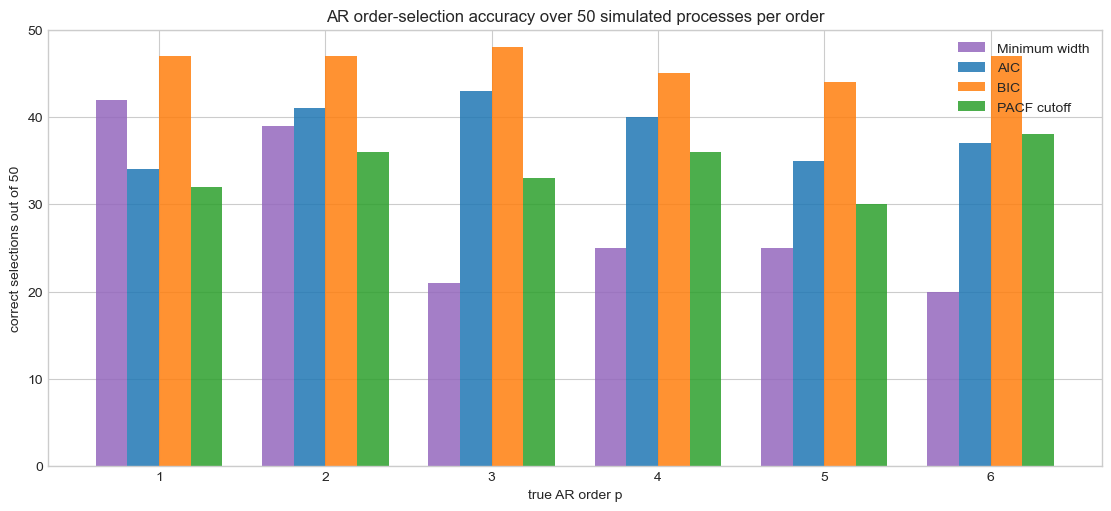

In [151]:
comparison_replications = 50
comparison_maximum_order = 10

order_comparison_results = run_order_selection_comparison(
    orders=range(1, 7),
    replications=comparison_replications,
    maximum_order=comparison_maximum_order,
    sample_size=2_000,
    burnin=1_000,
    innovation_half_width=1.0,
    width_iterations=2_000,
    width_restarts=1,
    width_patience=200,
    width_initial_step=0.2,
    plateau_tolerance=plateau_relative_tolerance,
    seed=20260810,
)

order_comparison_summary = (
    order_comparison_results
    .groupby(["true_order", "method"])["correct"]
    .agg(correct_count="sum", accuracy="mean")
    .reset_index()
)

correct_count_table = order_comparison_summary.pivot(
    index="true_order",
    columns="method",
    values="correct_count",
)
accuracy_table = order_comparison_summary.pivot(
    index="true_order",
    columns="method",
    values="accuracy",
)

print("Correct selections out of", comparison_replications)
print(correct_count_table.to_string())
print("\nAccuracy")
print(accuracy_table.round(3).to_string())

methods = ["Minimum width", "AIC", "BIC", "PACF cutoff"]
colors = ["tab:purple", "tab:blue", "tab:orange", "tab:green"]
true_orders = np.arange(1, 7)
bar_width = 0.19

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for method_index, (method, color) in enumerate(zip(methods, colors)):
    offset = (method_index - (len(methods) - 1) / 2) * bar_width
    counts = correct_count_table.loc[true_orders, method].to_numpy()
    ax.bar(
        true_orders + offset,
        counts,
        width=bar_width,
        label=method,
        color=color,
        alpha=0.85,
    )

ax.set(
    title="AR order-selection accuracy over 50 simulated processes per order",
    xlabel="true AR order p",
    ylabel="correct selections out of 50",
    xticks=true_orders,
    ylim=(0, comparison_replications),
)
ax.legend()
plt.show()


## Smoothed Riemannian minimization and method comparison

The second minimizer replaces the two maxima in the empirical width by stable log-sum-exp approximations, optimizes each smooth problem on the unit sphere with Riemannian gradient descent and Armijo backtracking, and halves the smoothing parameter between stages. Each stage warm-starts the next. The first automatic restart is the smallest-covariance eigenvector and the others are random. The final reported value is always the original nonsmoothed empirical width.

The experiment below gives both methods the same simulated point clouds and the same initial directions. It compares the exact width at the returned direction, wall-clock time, and objective/gradient evaluations across embedding dimensions.

In [ ]:
"""Log-sum-exp continuation for empirical minimum width on a sphere."""

from __future__ import annotations

from time import perf_counter

import numpy as np
import pandas as pd
from scipy.special import logsumexp


def empirical_directional_width(points, direction):
    """Evaluate the original, nonsmoothed empirical directional width."""
    points = np.asarray(points, dtype=float)
    direction = np.asarray(direction, dtype=float)
    if points.ndim != 2 or len(points) < 2:
        raise ValueError("points must have shape (n, k) with n >= 2.")
    if direction.shape != (points.shape[1],):
        raise ValueError(f"direction must have shape ({points.shape[1]},).")
    norm = np.linalg.norm(direction)
    if norm <= np.finfo(float).eps:
        raise ValueError("direction must be nonzero.")
    projections = points @ (direction / norm)
    return float(np.max(projections) - np.min(projections))


def _smoothed_width_value_gradient(points, direction, mu):
    """Stable log-sum-exp width and Riemannian gradient on the sphere."""
    projections = points @ direction
    positive_scores = projections / mu
    negative_scores = -positive_scores

    positive_log_sum = logsumexp(positive_scores)
    negative_log_sum = logsumexp(negative_scores)
    positive_weights = np.exp(positive_scores - positive_log_sum)
    negative_weights = np.exp(negative_scores - negative_log_sum)

    value = mu * (positive_log_sum + negative_log_sum)
    ambient_gradient = positive_weights @ points - negative_weights @ points
    gradient = ambient_gradient - (direction @ ambient_gradient) * direction
    return float(value), gradient


def _project_tangent(vector, direction):
    return vector - (direction @ vector) * direction


def _riemannian_gradient_descent_sphere(
    points,
    initial_direction,
    mu,
    maximum_iterations=100,
    gradient_tolerance=1e-7,
    initial_step=1.0,
    armijo_constant=1e-4,
    line_search_contraction=0.5,
    minimum_step=1e-12,
):
    """Solve one smooth continuation stage with Riemannian gradient descent."""
    direction = np.asarray(initial_direction, dtype=float).copy()
    direction_norm = np.linalg.norm(direction)
    if direction_norm <= np.finfo(float).eps:
        raise ValueError("initial_direction must be nonzero.")
    direction /= direction_norm

    value, gradient = _smoothed_width_value_gradient(points, direction, mu)
    evaluations = 1
    accepted_iterations = 0
    status = "maximum_iterations"

    for iteration in range(maximum_iterations):
        gradient_norm = np.linalg.norm(gradient)
        if gradient_norm <= gradient_tolerance:
            status = "gradient_tolerance"
            break

        # The negative Riemannian gradient is a tangent descent direction.
        search_direction = -_project_tangent(gradient, direction)
        directional_derivative = -(gradient_norm**2)
        step_size = initial_step
        accepted = False

        while step_size >= minimum_step:
            # Normalization is a retraction from the tangent space to S^(k-1).
            candidate = direction + step_size * search_direction
            candidate_norm = np.linalg.norm(candidate)
            if candidate_norm <= np.finfo(float).eps:
                step_size *= line_search_contraction
                continue
            candidate /= candidate_norm
            candidate_value, candidate_gradient = _smoothed_width_value_gradient(
                points, candidate, mu
            )
            evaluations += 1
            if candidate_value <= (
                value
                + armijo_constant * step_size * directional_derivative
            ):
                accepted = True
                break
            step_size *= line_search_contraction

        if not accepted:
            status = "line_search_failed"
            break

        direction = candidate
        value = candidate_value
        gradient = candidate_gradient
        accepted_iterations = iteration + 1

    return {
        "direction": direction,
        "smoothed_objective": value,
        "gradient_norm": float(np.linalg.norm(gradient)),
        "iterations": accepted_iterations,
        "evaluations": evaluations,
        "status": status,
    }


def smoothed_riemannian_empirical_width(
    points,
    restarts=8,
    initial_mu=None,
    continuation_factor=0.5,
    relative_smoothing_tolerance=1e-3,
    maximum_iterations_per_stage=100,
    gradient_tolerance=1e-7,
    initial_step=1.0,
    rng=None,
    initial_directions=None,
):
    """Minimize empirical width by smooth continuation on the unit sphere.

    The first automatic start is the minimum-covariance eigenvector. Other
    starts are random. The reported minimum is always evaluated with the
    original nonsmooth width, and continuation stops once 2*mu*log(n) is no
    larger than relative_smoothing_tolerance times a data width scale.
    """
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or len(points) < 2:
        raise ValueError("points must have shape (n, k) with n >= 2.")
    if not np.all(np.isfinite(points)):
        raise ValueError("points must contain only finite values.")
    if not isinstance(restarts, (int, np.integer)) or restarts < 1:
        raise ValueError("restarts must be a positive integer.")
    if not 0.0 < continuation_factor < 1.0:
        raise ValueError("continuation_factor must lie strictly between 0 and 1.")
    if relative_smoothing_tolerance <= 0.0:
        raise ValueError("relative_smoothing_tolerance must be positive.")
    if maximum_iterations_per_stage < 1 or initial_step <= 0.0:
        raise ValueError("iteration limit and initial_step must be positive.")

    # Width is translation invariant; centering improves numerical scaling.
    centered_points = points - np.mean(points, axis=0)
    observation_count, dimension = centered_points.shape
    width_scale = float(np.max(np.ptp(centered_points, axis=0)))
    if width_scale <= np.finfo(float).eps:
        direction = np.zeros(dimension)
        direction[0] = 1.0
        return {
            "minimum_width": 0.0,
            "direction": direction,
            "continuation_history": pd.DataFrame(),
            "restart_summaries": pd.DataFrame(),
            "final_mu": 0.0,
            "smoothing_error_bound": 0.0,
            "total_evaluations": 0,
        }

    if dimension == 1:
        direction = np.ones(1)
        minimum_width = empirical_directional_width(centered_points, direction)
        return {
            "minimum_width": minimum_width,
            "direction": direction,
            "continuation_history": pd.DataFrame(),
            "restart_summaries": pd.DataFrame([{
                "restart": 0,
                "minimum_width": minimum_width,
                "evaluations": 0,
            }]),
            "final_mu": 0.0,
            "smoothing_error_bound": 0.0,
            "total_evaluations": 0,
        }

    log_observation_count = np.log(observation_count)
    absolute_tolerance = relative_smoothing_tolerance * width_scale
    target_mu = absolute_tolerance / (2.0 * log_observation_count)
    if initial_mu is None:
        initial_mu = 0.25 * width_scale
    if initial_mu <= 0.0:
        raise ValueError("initial_mu must be positive.")

    mu_values = [max(float(initial_mu), target_mu)]
    while mu_values[-1] * continuation_factor > target_mu:
        mu_values.append(mu_values[-1] * continuation_factor)
    if mu_values[-1] > target_mu * (1.0 + 1e-12):
        mu_values.append(target_mu)

    generator = np.random.default_rng(rng)
    if initial_directions is None:
        covariance = centered_points.T @ centered_points / observation_count
        _, eigenvectors = np.linalg.eigh(covariance)
        starts = [eigenvectors[:, 0]]
        starts.extend(
            generator.normal(size=dimension) for _ in range(restarts - 1)
        )
    else:
        starts_array = np.asarray(initial_directions, dtype=float)
        if starts_array.ndim == 1:
            starts_array = starts_array[None, :]
        if (
            starts_array.ndim != 2
            or starts_array.shape[1] != dimension
            or len(starts_array) < 1
        ):
            raise ValueError(
                f"initial_directions must have shape (m, {dimension})."
            )
        starts = list(starts_array)

    normalized_starts = []
    for start in starts:
        start_norm = np.linalg.norm(start)
        if start_norm <= np.finfo(float).eps:
            raise ValueError("Every initial direction must be nonzero.")
        normalized_starts.append(start / start_norm)

    continuation_rows = []
    restart_rows = []
    best_width = np.inf
    best_direction = None
    total_evaluations = 0

    for restart_index, start in enumerate(normalized_starts):
        direction = start
        restart_evaluations = 0
        for stage_index, mu in enumerate(mu_values):
            stage_fit = _riemannian_gradient_descent_sphere(
                centered_points,
                direction,
                mu,
                maximum_iterations=maximum_iterations_per_stage,
                gradient_tolerance=gradient_tolerance,
                initial_step=initial_step,
            )
            direction = stage_fit["direction"]
            restart_evaluations += stage_fit["evaluations"]
            continuation_rows.append({
                "restart": restart_index,
                "stage": stage_index,
                "mu": mu,
                "smoothing_error_bound": 2.0 * mu * log_observation_count,
                "exact_width": empirical_directional_width(
                    centered_points, direction
                ),
                "smoothed_objective": stage_fit["smoothed_objective"],
                "gradient_norm": stage_fit["gradient_norm"],
                "iterations": stage_fit["iterations"],
                "evaluations": stage_fit["evaluations"],
                "status": stage_fit["status"],
            })

        exact_width = empirical_directional_width(centered_points, direction)
        restart_rows.append({
            "restart": restart_index,
            "minimum_width": exact_width,
            "evaluations": restart_evaluations,
        })
        total_evaluations += restart_evaluations
        if exact_width < best_width:
            best_width = exact_width
            best_direction = direction.copy()

    return {
        "minimum_width": float(best_width),
        "direction": best_direction,
        "continuation_history": pd.DataFrame(continuation_rows),
        "restart_summaries": pd.DataFrame(restart_rows),
        "final_mu": float(mu_values[-1]),
        "smoothing_error_bound": float(
            2.0 * mu_values[-1] * log_observation_count
        ),
        "total_evaluations": int(total_evaluations),
    }


In [ ]:
# Controlled comparison of the two arbitrary-dimensional minimizers.
method_comparison_dimensions = (2, 5, 10, 20, 50, 100)
method_comparison_replications = 2
method_comparison_restarts = 3
method_comparison_sample_size = 800
method_comparison_subgradient_iterations = 1_000
method_comparison_seed = 20260811

minimizer_comparison_rows = []

for replication in range(method_comparison_replications):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        method_comparison_seed, replication, 0
    ]))
    comparison_phi = jones_ar_coefficients(
        p=4, rng=process_generator
    )
    comparison_series = simulate_uniform_ar(
        comparison_phi,
        sample_size=method_comparison_sample_size,
        burnin=1_000,
        half_width=1.0,
        rng=process_generator,
    )

    for dimension in method_comparison_dimensions:
        cloud = sliding_window_point_cloud(
            comparison_series,
            embedding_dimension=dimension,
        )
        centered_cloud = cloud - np.mean(cloud, axis=0)
        covariance = centered_cloud.T @ centered_cloud / len(centered_cloud)
        _, covariance_eigenvectors = np.linalg.eigh(covariance)
        start_generator = np.random.default_rng(np.random.SeedSequence([
            method_comparison_seed, replication, dimension
        ]))
        shared_starts = [covariance_eigenvectors[:, 0]]
        shared_starts.extend(
            start_generator.normal(size=dimension)
            for _ in range(method_comparison_restarts - 1)
        )
        shared_starts = np.asarray([
            start / np.linalg.norm(start) for start in shared_starts
        ])

        start_time = perf_counter()
        subgradient_fits = [
            projected_subgradient_empirical_width(
                cloud,
                iterations=method_comparison_subgradient_iterations,
                initial_step=0.2,
                patience=250,
                initial_direction=start,
                rng=method_comparison_seed,
            )
            for start in shared_starts
        ]
        subgradient_time = perf_counter() - start_time
        subgradient_fit = min(
            subgradient_fits,
            key=lambda fit: fit["minimum_width"],
        )
        subgradient_evaluations = sum(
            len(fit["width_history"]) for fit in subgradient_fits
        )

        start_time = perf_counter()
        smoothing_fit = smoothed_riemannian_empirical_width(
            cloud,
            initial_directions=shared_starts,
            continuation_factor=0.5,
            relative_smoothing_tolerance=1e-2,
            maximum_iterations_per_stage=60,
            gradient_tolerance=1e-7,
        )
        smoothing_time = perf_counter() - start_time

        method_results = [
            (
                "Projected subgradient",
                subgradient_fit,
                subgradient_time,
                subgradient_evaluations,
            ),
            (
                "Smoothed Riemannian gradient descent",
                smoothing_fit,
                smoothing_time,
                smoothing_fit["total_evaluations"],
            ),
        ]
        best_observed_width = min(
            result[1]["minimum_width"] for result in method_results
        )
        for method, fit, elapsed_time, evaluations in method_results:
            minimizer_comparison_rows.append({
                "replication": replication,
                "dimension": dimension,
                "method": method,
                "minimum_width": fit["minimum_width"],
                "relative_gap_to_best": (
                    fit["minimum_width"] / best_observed_width - 1.0
                ),
                "runtime_seconds": elapsed_time,
                "objective_gradient_evaluations": evaluations,
            })

        print(
            f"Completed replication {replication + 1}/"
            f"{method_comparison_replications}, k={dimension}"
        )

minimizer_comparison = pd.DataFrame(minimizer_comparison_rows)
minimizer_comparison_summary = (
    minimizer_comparison
    .groupby(["dimension", "method"])
    .agg(
        mean_minimum_width=("minimum_width", "mean"),
        mean_relative_gap=("relative_gap_to_best", "mean"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        mean_evaluations=("objective_gradient_evaluations", "mean"),
    )
    .reset_index()
)

print("\nMean results over", method_comparison_replications, "replications")
print(
    minimizer_comparison_summary.round({
        "mean_minimum_width": 6,
        "mean_relative_gap": 6,
        "mean_runtime_seconds": 4,
        "mean_evaluations": 1,
    }).to_string(index=False)
)

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.4), constrained_layout=True
)
comparison_styles = {
    "Projected subgradient": ("tab:blue", "o"),
    "Smoothed Riemannian gradient descent": ("tab:orange", "s"),
}
for method, (color, marker) in comparison_styles.items():
    method_summary = minimizer_comparison_summary[
        minimizer_comparison_summary["method"] == method
    ]
    axes[0].plot(
        method_summary["dimension"],
        method_summary["mean_minimum_width"],
        color=color,
        marker=marker,
        linewidth=2,
        label=method,
    )
    axes[1].plot(
        method_summary["dimension"],
        100.0 * method_summary["mean_relative_gap"],
        color=color,
        marker=marker,
        linewidth=2,
        label=method,
    )
    axes[2].plot(
        method_summary["dimension"],
        method_summary["mean_runtime_seconds"],
        color=color,
        marker=marker,
        linewidth=2,
        label=method,
    )

axes[0].set(
    title="Exact width at returned direction",
    xlabel="embedding dimension k",
    ylabel="mean empirical width",
    xticks=method_comparison_dimensions,
)
axes[1].set(
    title="Optimization quality",
    xlabel="embedding dimension k",
    ylabel="mean gap to best observed (%)",
    xticks=method_comparison_dimensions,
)
axes[2].set(
    title="Wall-clock cost",
    xlabel="embedding dimension k",
    ylabel="mean runtime (seconds)",
    xticks=method_comparison_dimensions,
)
axes[2].set_yscale("log")
for axis in axes:
    axis.legend()
plt.show()

## Grid epsilon-kernel coreset

The next function implements the grid construction behind Lemma 3.5 of Agarwal, Har-Peled, and Varadarajan, *Approximating Extent Measures of Points*. It first centers and whitens the affine hull of the cloud to obtain a computable lower bound on every directional width. It then places the transformed cloud on the paper's grid and retains one point from the lowest and highest occupied cell in every grid column.

The returned points are always a subset of the original cloud. The construction has exponential dependence on the effective dimension, so the function emits a warning when the ambient dimension exceeds five.

In [61]:
import warnings


def epsilon_kernel_grid_coreset(
    points,
    epsilon=0.10,
    warn_above_dimension=5,
    rank_tolerance=None,
):
    """Construct a grid epsilon-kernel following Lemma 3.5 of AHV (2004).

    Whitening is an invertible affine fattening transformation on the affine
    hull. In whitened coordinates every unit-direction projection has
    variance one, hence range at least two by Popoviciu's inequality. Scaling
    into the unit cube therefore supplies the alpha lower bound required by
    the grid proof.

    Returns the original point indices as well as the coreset itself. The
    theoretical grid complexity is exponential in the effective dimension.
    """
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or len(points) < 2:
        raise ValueError("points must have shape (n, k) with n >= 2.")
    if not np.all(np.isfinite(points)):
        raise ValueError("points must contain only finite values.")
    if not 0.0 < epsilon < 1.0:
        raise ValueError("epsilon must lie strictly between zero and one.")

    observation_count, ambient_dimension = points.shape
    if ambient_dimension > warn_above_dimension:
        warnings.warn(
            "The epsilon-kernel grid has exponential dimension dependence; "
            f"k={ambient_dimension} exceeds {warn_above_dimension}. The "
            "coreset may contain nearly every input point.",
            RuntimeWarning,
            stacklevel=2,
        )

    centered_points = points - np.mean(points, axis=0)
    covariance = centered_points.T @ centered_points / observation_count
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    largest_eigenvalue = max(float(eigenvalues[-1]), 0.0)

    if rank_tolerance is None:
        rank_tolerance = (
            np.finfo(float).eps
            * max(observation_count, ambient_dimension)
            * max(largest_eigenvalue, 1.0)
        )
    if rank_tolerance < 0.0:
        raise ValueError("rank_tolerance must be nonnegative.")

    positive = eigenvalues > rank_tolerance
    effective_dimension = int(np.count_nonzero(positive))
    if effective_dimension == 0:
        indices = np.array([0], dtype=int)
        return {
            "coreset": points[indices].copy(),
            "indices": indices,
            "epsilon": float(epsilon),
            "original_size": observation_count,
            "coreset_size": 1,
            "reduction_fraction": 1.0 - 1.0 / observation_count,
            "ambient_dimension": ambient_dimension,
            "effective_dimension": 0,
            "alpha_lower_bound": 1.0,
            "grid_spacing": np.inf,
            "inverse_grid_spacing": 0,
        }

    affine_basis = eigenvectors[:, positive]
    whitened_points = (
        centered_points @ affine_basis
        / np.sqrt(eigenvalues[positive])
    )

    # Scalar scaling places the whitened cloud in [-1, 1]^r.
    cube_scale = float(np.max(np.abs(whitened_points)))
    normalized_points = whitened_points / cube_scale
    alpha_lower_bound = min(1.0, 1.0 / cube_scale)

    # The paper chooses the largest delta with 1/delta integral and
    # delta <= epsilon*alpha/sqrt(r).
    inverse_grid_spacing = int(np.ceil(
        np.sqrt(effective_dimension)
        / (epsilon * alpha_lower_bound)
    ))
    grid_spacing = 1.0 / inverse_grid_spacing
    cell_coordinates = np.floor(
        normalized_points / grid_spacing
    ).astype(np.int64)

    # For each column in the first r-1 coordinates, retain a point from
    # the lowest and highest occupied cell in the final coordinate.
    column_extremes = {}
    for point_index, cell in enumerate(cell_coordinates):
        column = tuple(int(value) for value in cell[:-1])
        height = int(cell[-1])
        if column not in column_extremes:
            column_extremes[column] = [
                height,
                point_index,
                height,
                point_index,
            ]
            continue

        record = column_extremes[column]
        if height < record[0]:
            record[0] = height
            record[1] = point_index
        if height > record[2]:
            record[2] = height
            record[3] = point_index

    selected_indices = sorted({
        point_index
        for record in column_extremes.values()
        for point_index in (record[1], record[3])
    })
    selected_indices = np.asarray(selected_indices, dtype=int)

    return {
        "coreset": points[selected_indices].copy(),
        "indices": selected_indices,
        "epsilon": float(epsilon),
        "original_size": observation_count,
        "coreset_size": len(selected_indices),
        "reduction_fraction": (
            1.0 - len(selected_indices) / observation_count
        ),
        "ambient_dimension": ambient_dimension,
        "effective_dimension": effective_dimension,
        "alpha_lower_bound": float(alpha_lower_bound),
        "grid_spacing": float(grid_spacing),
        "inverse_grid_spacing": inverse_grid_spacing,
    }

P_3 to Q_3 reduction
 epsilon  P_3 points  Q_3 points  points removed  reduction percent  largest sampled width loss
    0.05         998         998               0                0.0                         0.0
    0.10         998         985              13                1.3                         0.0
    0.20         998         871             127               12.7                         0.0
    0.30         998         682             316               31.7                         0.0

For epsilon=0.20: |P_3|=998, |Q_3|=871, removed=127 (12.7%).


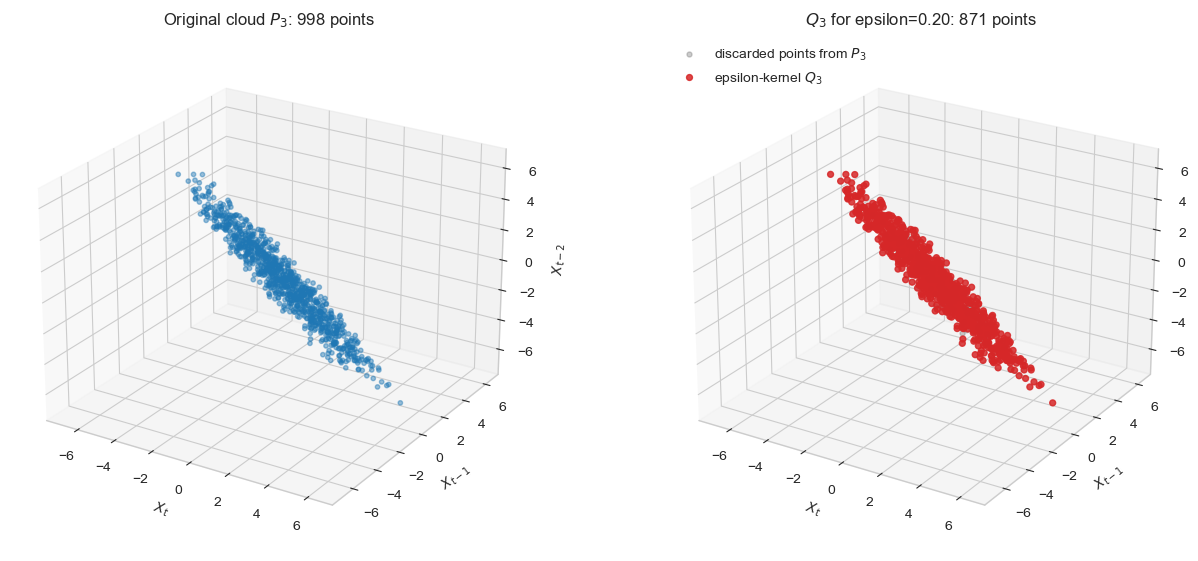

In [62]:
# Small coreset experiment: compare the three-dimensional cloud P_3 with Q_3.
P_3 = cloud_3d.copy()
epsilon_kernel_values = (0.05, 0.10, 0.20, 0.30)
epsilon_kernel_validation_directions = 10_000
epsilon_kernel_seed = 20260812

validation_generator = np.random.default_rng(epsilon_kernel_seed)
validation_directions = validation_generator.normal(
    size=(epsilon_kernel_validation_directions, P_3.shape[1])
)
validation_directions /= np.linalg.norm(
    validation_directions, axis=1, keepdims=True
)
full_validation_widths = np.ptp(
    P_3 @ validation_directions.T,
    axis=0,
)

epsilon_kernel_fits_3 = {}
epsilon_kernel_rows_3 = []
for epsilon_value in epsilon_kernel_values:
    kernel_fit = epsilon_kernel_grid_coreset(
        P_3,
        epsilon=epsilon_value,
    )
    epsilon_kernel_fits_3[epsilon_value] = kernel_fit
    Q_candidate = kernel_fit["coreset"]
    coreset_validation_widths = np.ptp(
        Q_candidate @ validation_directions.T,
        axis=0,
    )
    sampled_relative_losses = (
        1.0 - coreset_validation_widths / full_validation_widths
    )
    epsilon_kernel_rows_3.append({
        "epsilon": epsilon_value,
        "P_3 points": len(P_3),
        "Q_3 points": len(Q_candidate),
        "points removed": len(P_3) - len(Q_candidate),
        "reduction percent": (
            100.0 * kernel_fit["reduction_fraction"]
        ),
        "largest sampled width loss": np.max(sampled_relative_losses),
    })

epsilon_kernel_comparison_3 = pd.DataFrame(epsilon_kernel_rows_3)
print("P_3 to Q_3 reduction")
print(
    epsilon_kernel_comparison_3.round({
        "reduction percent": 1,
        "largest sampled width loss": 5,
    }).to_string(index=False)
)

epsilon_for_Q_3 = 0.20
epsilon_kernel_fit_3 = epsilon_kernel_fits_3[epsilon_for_Q_3]
Q_3 = epsilon_kernel_fit_3["coreset"]
Q_3_indices = epsilon_kernel_fit_3["indices"]
discarded_mask_3 = np.ones(len(P_3), dtype=bool)
discarded_mask_3[Q_3_indices] = False
discarded_P_3 = P_3[discarded_mask_3]

print(
    f"\nFor epsilon={epsilon_for_Q_3:.2f}: "
    f"|P_3|={len(P_3)}, |Q_3|={len(Q_3)}, "
    f"removed={len(P_3) - len(Q_3)} "
    f"({100.0 * epsilon_kernel_fit_3['reduction_fraction']:.1f}%)."
)

coordinate_limits = np.column_stack((
    np.min(P_3, axis=0),
    np.max(P_3, axis=0),
))
coordinate_padding = 0.05 * np.maximum(
    coordinate_limits[:, 1] - coordinate_limits[:, 0],
    np.finfo(float).eps,
)

fig = plt.figure(figsize=(13, 5.5), constrained_layout=True)
axis_P_3 = fig.add_subplot(1, 2, 1, projection="3d")
axis_Q_3 = fig.add_subplot(1, 2, 2, projection="3d")

axis_P_3.scatter(
    P_3[:, 0], P_3[:, 1], P_3[:, 2],
    color="tab:blue", s=10, alpha=0.45,
)
axis_Q_3.scatter(
    discarded_P_3[:, 0], discarded_P_3[:, 1], discarded_P_3[:, 2],
    color="gray", s=13, alpha=0.40,
    label=r"discarded points from $P_3$",
)
axis_Q_3.scatter(
    Q_3[:, 0], Q_3[:, 1], Q_3[:, 2],
    color="tab:red", s=18, alpha=0.85,
    label=r"epsilon-kernel $Q_3$",
)

axis_P_3.set_title(fr"Original cloud $P_3$: {len(P_3)} points")
axis_Q_3.set_title(
    fr"$Q_3$ for epsilon={epsilon_for_Q_3:.2f}: {len(Q_3)} points"
)
for axis in (axis_P_3, axis_Q_3):
    axis.set(
        xlabel=r"$X_t$",
        ylabel=r"$X_{t-1}$",
        zlabel=r"$X_{t-2}$",
    )
    axis.set_xlim(
        coordinate_limits[0, 0] - coordinate_padding[0],
        coordinate_limits[0, 1] + coordinate_padding[0],
    )
    axis.set_ylim(
        coordinate_limits[1, 0] - coordinate_padding[1],
        coordinate_limits[1, 1] + coordinate_padding[1],
    )
    axis.set_zlim(
        coordinate_limits[2, 0] - coordinate_padding[2],
        coordinate_limits[2, 1] + coordinate_padding[2],
    )
    axis.view_init(elev=24, azim=-58)

axis_Q_3.legend(loc="upper left")
plt.show()